# Banking Customer 360 Analytics
## 04 - Exploratory Data Analysis

Purpose: Explore customer demographics, financial behavior, transactions, loans, service interactions, and churn using the finalized Customer 360 dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

file_path = Path("../data/final/customer_360.csv")

customer_360 = pd.read_csv(file_path)

print("Dataset shape:", customer_360.shape)
print("\nColumns:")
print(customer_360.columns.tolist())

Dataset shape: (5000, 29)

Columns:
['customer_id', 'age', 'gender', 'country', 'occupation', 'annual_income', 'credit_score', 'tenure_years', 'join_date', 'last_transaction_date', 'late_loan_count', 'default_loan_count', 'complaint_count', 'escalated_count', 'total_balance', 'active_account_count', 'recency_days', 'products_number', 'churn', 'loan_to_income_ratio', 'account_count', 'total_transactions', 'total_transaction_value', 'avg_transaction_value', 'loan_count', 'total_loan_amount', 'average_interest_rate', 'total_service_interactions', 'average_resolution_days']


In [2]:
customer_360.head()

,customer_id,age,gender,country,occupation,annual_income,credit_score,tenure_years,join_date,last_transaction_date,late_loan_count,default_loan_count,complaint_count,escalated_count,total_balance,active_account_count,recency_days,products_number,churn,loan_to_income_ratio,account_count,total_transactions,total_transaction_value,avg_transaction_value,loan_count,total_loan_amount,average_interest_rate,total_service_interactions,average_resolution_days
0,C00001,25,Male,France,Salaried,25700,577,7,2025-02-22,2025-12-25,0,0,1,0,"337,661.45",4,6,4,0,0.00,4.00,22.00,"5,140.08",233.64,0.00,0.00,0.00,1.00,8.00
1,C00002,59,Male,Germany,Salaried,99800,682,12,2021-08-05,2025-12-18,0,0,2,0,"20,846.07",1,13,1,0,0.00,1.00,21.00,"6,220.92",296.23,0.00,0.00,0.00,2.00,11.50
2,C00003,53,Female,Spain,Salaried,102200,786,11,2016-06-20,2025-12-19,0,0,1,0,"46,466.48",2,12,3,0,2.57,2.00,16.00,"4,599.73",287.48,1.00,"262,227.49",9.12,1.00,6.00
3,C00004,42,Female,France,Self-Employed,48500,725,8,2016-11-17,2025-12-25,0,0,1,0,"208,178.52",1,6,1,0,0.00,1.00,15.00,"3,998.08",266.54,0.00,0.00,0.00,1.00,2.00
4,C00005,42,Female,France,Self-Employed,75900,624,9,2023-07-22,2025-12-12,0,0,1,0,"99,225.27",2,19,2,0,0.00,2.00,19.00,"7,296.95",384.05,0.00,0.00,0.00,1.00,8.00


## 5.1 Customer Demographics

This section examines the age, gender, country, occupation, and income profile of the bank's customers.

In [3]:
# Basic demographic statistics

print("Age statistics:")
print(customer_360["age"].describe())

print("\nGender distribution:")
print(customer_360["gender"].value_counts())

print("\nCountry distribution:")
print(customer_360["country"].value_counts())

print("\nTop occupations:")
print(customer_360["occupation"].value_counts().head(10))

print("\nAnnual income statistics:")
print(customer_360["annual_income"].describe())

Age statistics:
count   5,000.00
mean       45.43
std        14.46
min        21.00
25%        33.00
50%        45.00
75%        58.00
max        70.00
Name: age, dtype: float64

Gender distribution:
gender
Male      2531
Female    2469
Name: count, dtype: int64

Country distribution:
country
France     2470
Germany    1328
Spain      1202
Name: count, dtype: int64

Top occupations:
occupation
Salaried          2266
Professional      1033
Self-Employed      735
Business Owner     580
Retired            386
Name: count, dtype: int64

Annual income statistics:
count     5,000.00
mean     66,168.90
std      31,580.54
min      18,000.00
25%      44,200.00
50%      59,400.00
75%      80,400.00
max     250,000.00
Name: annual_income, dtype: float64


### Demographic Visualizations

Visualize the age distribution and major customer segments by gender and country.

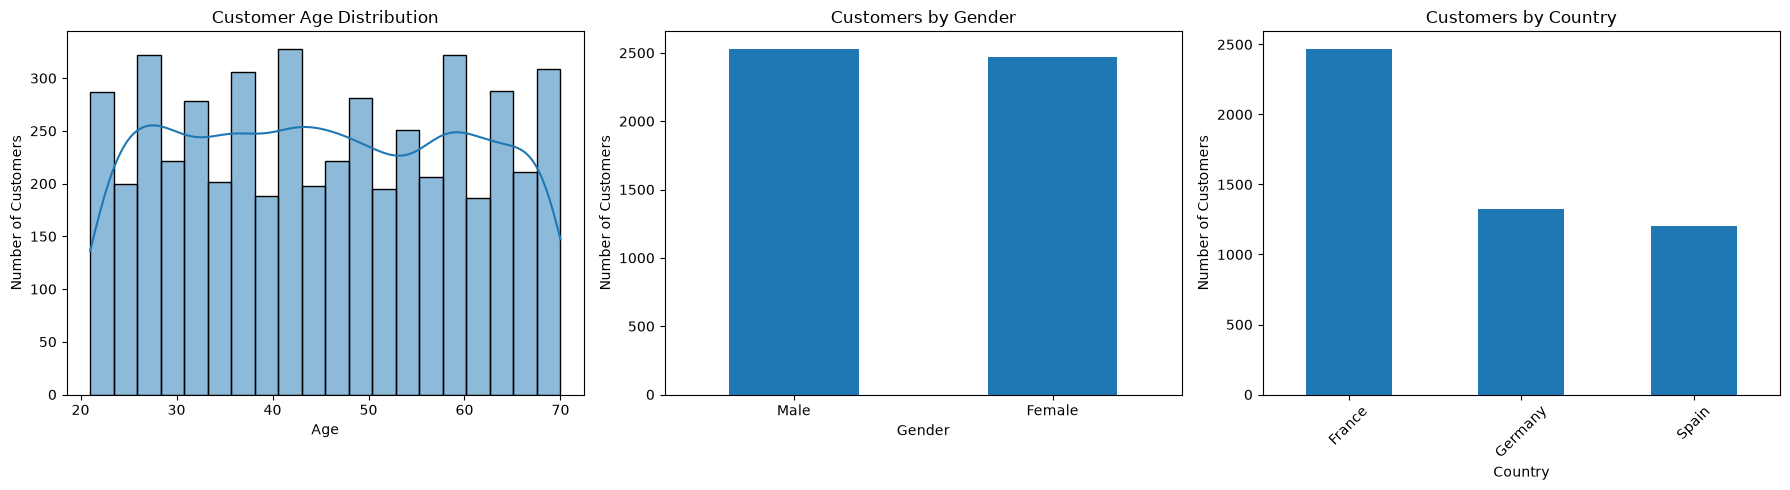

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Age distribution
sns.histplot(
    data=customer_360,
    x="age",
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Customers")

# Gender distribution
customer_360["gender"].value_counts().plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Customers by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Customers")
axes[1].tick_params(axis="x", rotation=0)

# Country distribution
customer_360["country"].value_counts().plot(
    kind="bar",
    ax=axes[2]
)
axes[2].set_title("Customers by Country")
axes[2].set_xlabel("Country")
axes[2].set_ylabel("Number of Customers")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 5.2 Customer Financial Profile

This section examines annual income, credit scores, account balances, and loan-to-income ratios to understand the financial profile of the customer base.

In [5]:
# Financial profile summary

financial_columns = [
    "annual_income",
    "credit_score",
    "total_balance",
    "loan_to_income_ratio",
    "total_loan_amount"
]

customer_360[financial_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
annual_income,"5,000.00","66,168.90","31,580.54","18,000.00","44,200.00","59,400.00","80,400.00","250,000.00"
credit_score,"5,000.00",652.54,80.02,354.00,597.00,653.00,707.00,850.00
total_balance,"5,000.00","85,935.03","115,899.48",0.00,"8,532.66","48,238.45","116,621.64","1,355,801.99"
loan_to_income_ratio,"5,000.00",3.41,7.80,0.00,0.00,0.00,3.06,98.34
total_loan_amount,"5,000.00","147,352.34","356,292.50",0.00,0.00,0.00,"104,560.43","3,322,170.32"


### Financial Profile Visualizations

The following visualizations show the distribution of customer income, credit scores, and account balances.

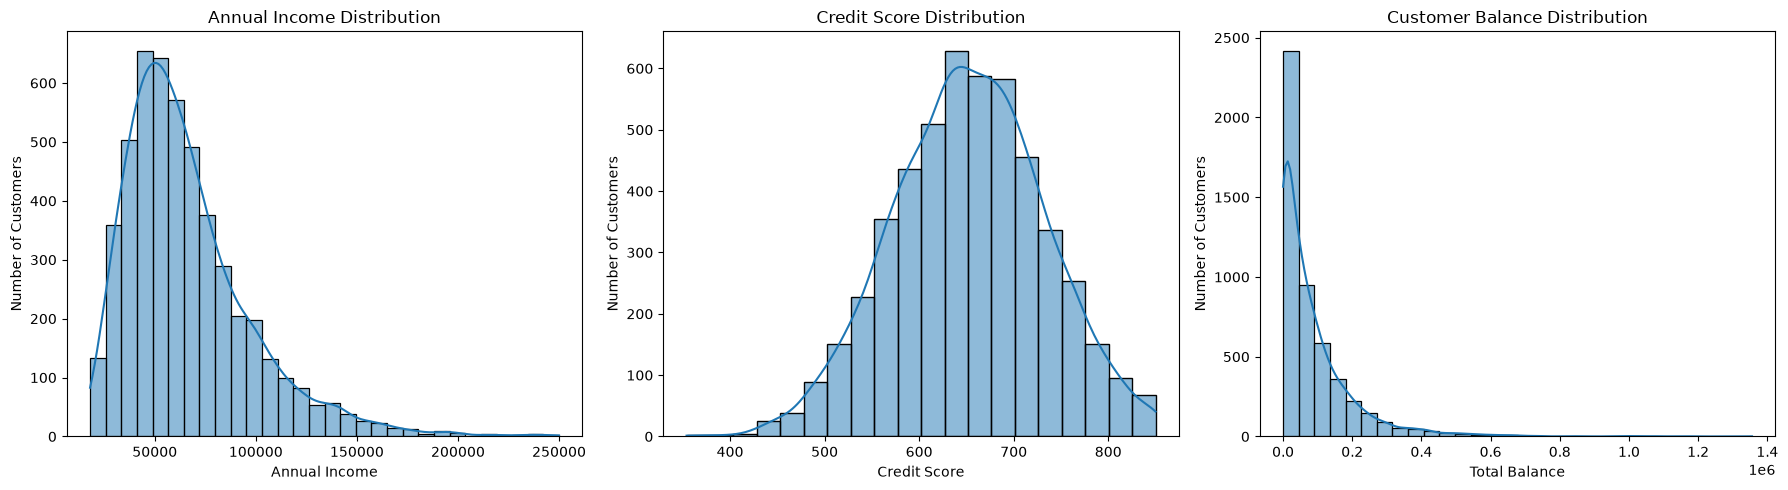

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Annual income
sns.histplot(
    data=customer_360,
    x="annual_income",
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Annual Income Distribution")
axes[0].set_xlabel("Annual Income")
axes[0].set_ylabel("Number of Customers")

# Credit score
sns.histplot(
    data=customer_360,
    x="credit_score",
    bins=20,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Credit Score Distribution")
axes[1].set_xlabel("Credit Score")
axes[1].set_ylabel("Number of Customers")

# Total balance
sns.histplot(
    data=customer_360,
    x="total_balance",
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Customer Balance Distribution")
axes[2].set_xlabel("Total Balance")
axes[2].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Income and Loan Exposure

Analyze the relationship between annual income and total loan amount to identify customers with higher borrowing exposure.

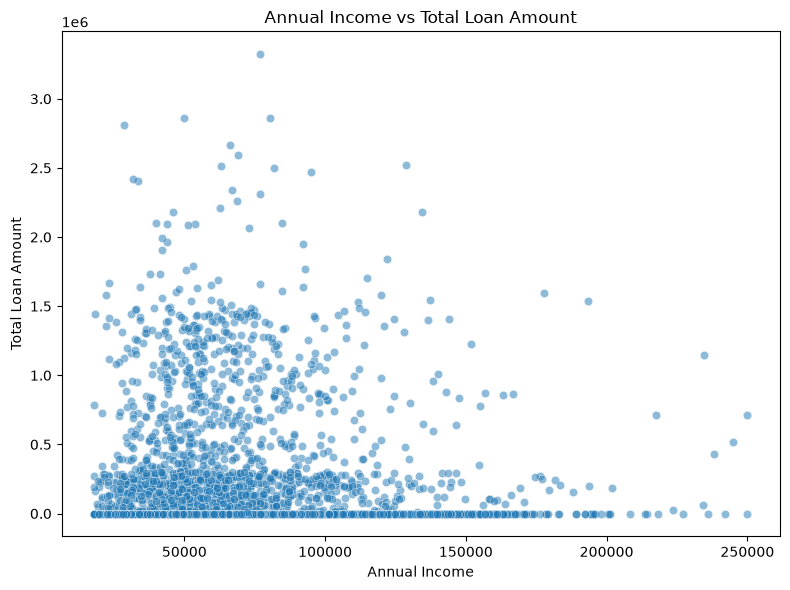

In [7]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=customer_360,
    x="annual_income",
    y="total_loan_amount",
    alpha=0.5
)

plt.title("Annual Income vs Total Loan Amount")
plt.xlabel("Annual Income")
plt.ylabel("Total Loan Amount")

plt.tight_layout()
plt.show()

## 5.3 Account and Transaction Behavior

This section examines customer account ownership, transaction activity, transaction values, and customer engagement with banking products.

In [8]:
# Account and transaction summary

transaction_columns = [
    "account_count",
    "active_account_count",
    "total_transactions",
    "total_transaction_value",
    "avg_transaction_value",
    "recency_days",
    "products_number"
]

customer_360[transaction_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
account_count,"5,000.00",1.50,1.23,0.00,1.00,1.00,2.00,8.00
active_account_count,"5,000.00",1.32,1.16,0.00,0.00,1.00,2.00,8.00
total_transactions,"5,000.00",15.48,9.20,0.00,12.00,18.00,22.00,36.00
total_transaction_value,"5,000.00","4,581.29","3,135.57",0.00,"2,685.39","4,911.20","6,592.68","22,745.51"
avg_transaction_value,"5,000.00",229.40,146.42,0.00,170.16,253.98,320.15,"1,137.28"
recency_days,"5,000.00",17.78,18.43,0.00,5.00,12.00,25.00,181.00
products_number,"5,000.00",2.00,1.41,0.00,1.00,2.00,3.00,9.00


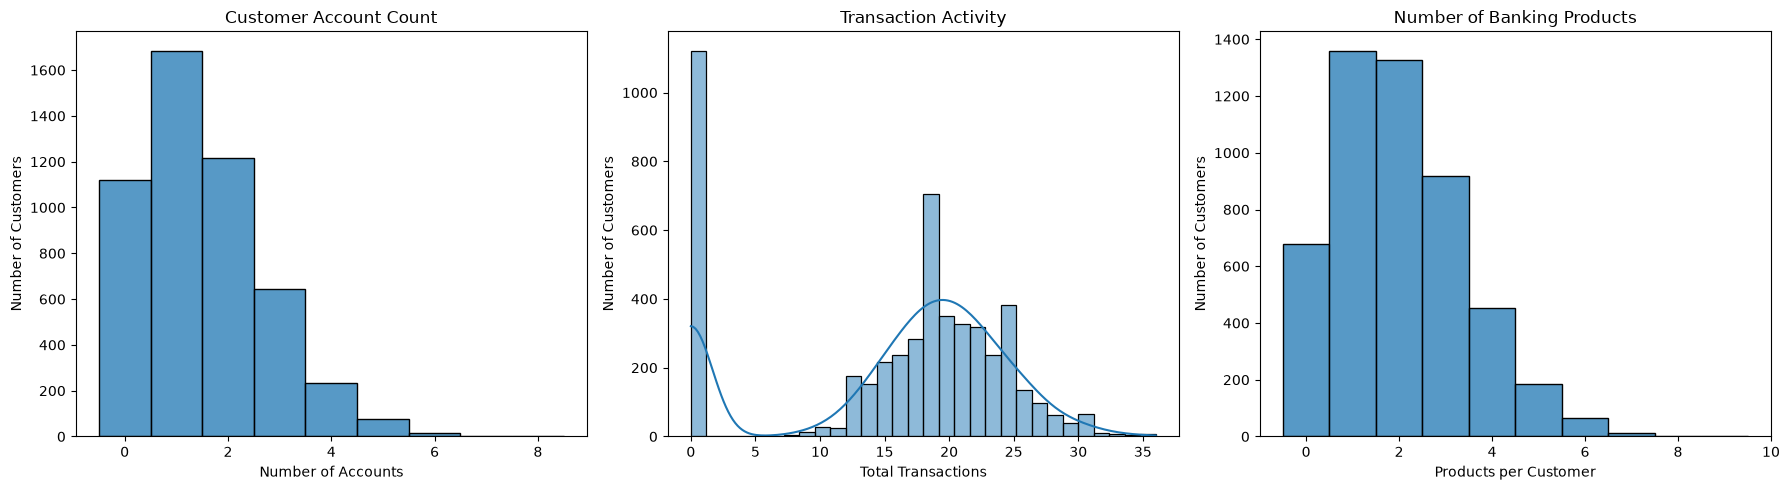

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Account count
sns.histplot(
    data=customer_360,
    x="account_count",
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Customer Account Count")
axes[0].set_xlabel("Number of Accounts")
axes[0].set_ylabel("Number of Customers")

# Transaction count
sns.histplot(
    data=customer_360,
    x="total_transactions",
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Transaction Activity")
axes[1].set_xlabel("Total Transactions")
axes[1].set_ylabel("Number of Customers")

# Product count
sns.histplot(
    data=customer_360,
    x="products_number",
    discrete=True,
    ax=axes[2]
)
axes[2].set_title("Number of Banking Products")
axes[2].set_xlabel("Products per Customer")
axes[2].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Transaction Activity and Value

Analyze whether customers with more transactions also generate higher transaction value.

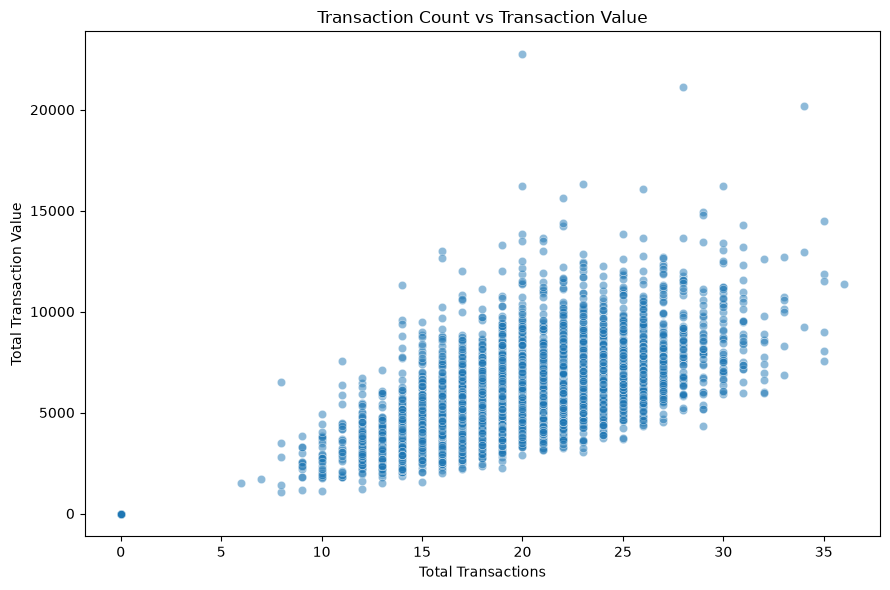

In [10]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=customer_360,
    x="total_transactions",
    y="total_transaction_value",
    alpha=0.5
)

plt.title("Transaction Count vs Transaction Value")
plt.xlabel("Total Transactions")
plt.ylabel("Total Transaction Value")

plt.tight_layout()
plt.show()

In [11]:
# Customer Engagement
customer_360["engagement_level"] = pd.cut(
    customer_360["total_transactions"],
    bins=[-1, 10, 20, 30, np.inf],
    labels=["Low", "Medium", "High", "Very High"]
)

print(
    customer_360["engagement_level"]
    .value_counts()
    .sort_index()
)

engagement_level
Low          1169
Medium       2145
High         1634
Very High      52
Name: count, dtype: int64


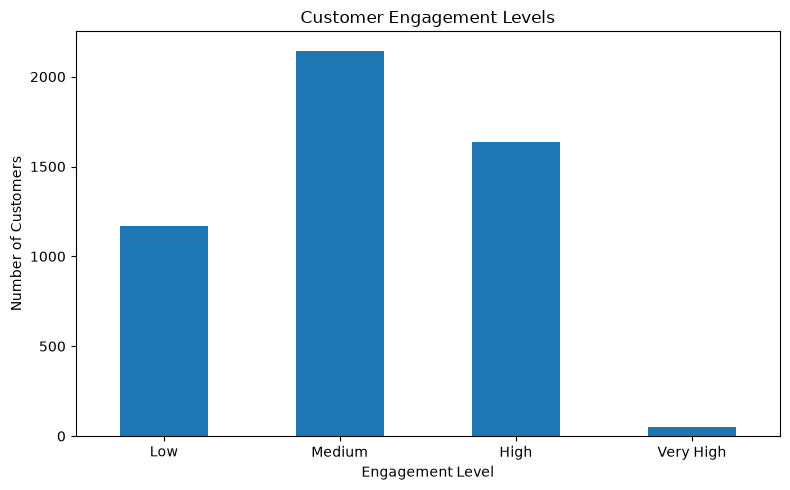

In [12]:
plt.figure(figsize=(8, 5))

customer_360["engagement_level"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Customer Engagement Levels")
plt.xlabel("Engagement Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Monthly Transaction Trend

Analyze how transaction activity and transaction value change over time.

In [13]:
# Load SQL-generated monthly transaction data

monthly_trend = pd.read_csv(
    "../outputs/exports/sql_monthly_trend.csv"
)

monthly_trend

,month,transactions,total_value
0,2025-01,8373,"2,458,029.22"
1,2025-02,7680,"2,277,370.96"
2,2025-03,8515,"2,503,891.13"
3,2025-04,8332,"2,456,636.56"
4,2025-05,8455,"2,504,956.68"
5,2025-06,8155,"2,442,658.97"
6,2025-07,8578,"2,574,138.97"
7,2025-08,8464,"2,484,014.77"
8,2025-09,8113,"2,402,499.13"
9,2025-10,8503,"2,533,894.51"


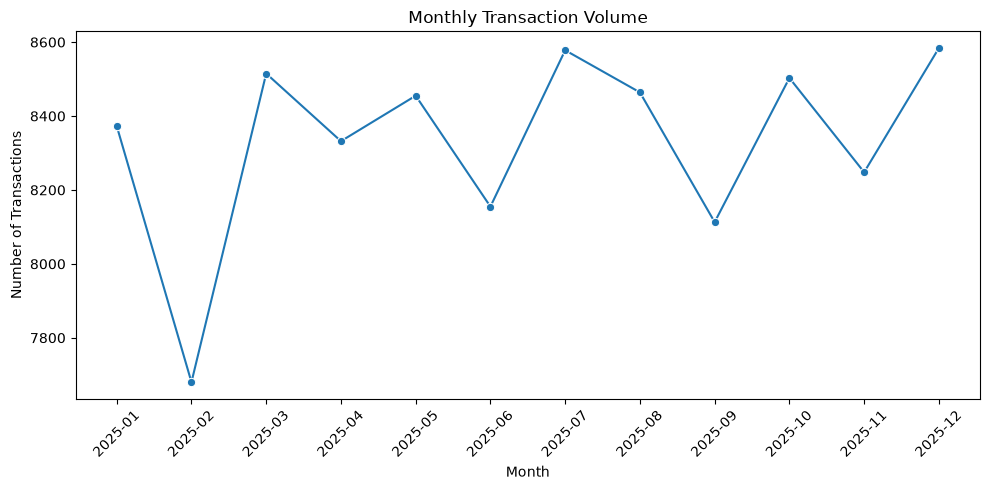

In [15]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_trend,
    x="month",
    y="transactions",
    marker="o"
)

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Transaction Value

Compare monthly transaction value to identify periods of stronger or weaker customer activity.

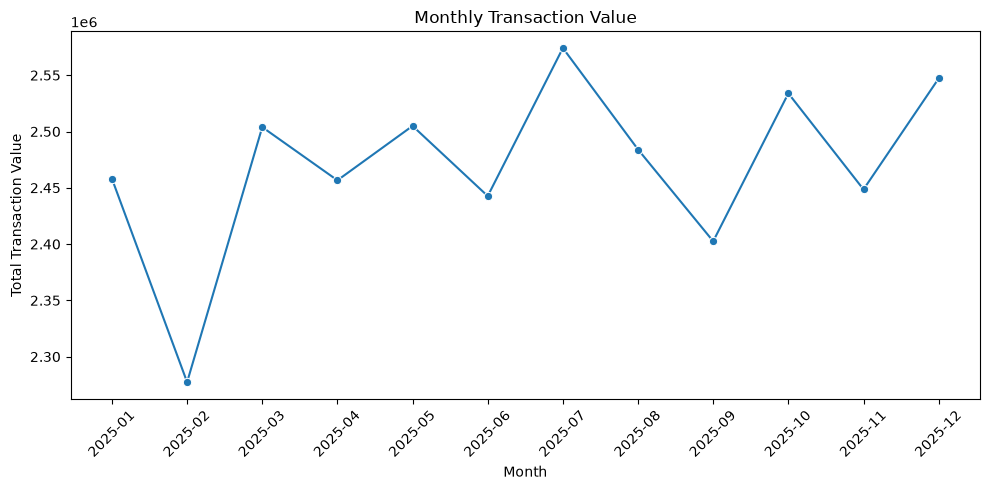

In [17]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_trend,
    x="month",
    y="total_value",
    marker="o"
)

plt.title("Monthly Transaction Value")
plt.xlabel("Month")
plt.ylabel("Total Transaction Value")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Transaction Channel Preference

Analyze which banking channels customers use most frequently and which channels generate the highest transaction value.

In [18]:
channel_preference = pd.read_csv(
    "../outputs/exports/sql_channel_preference.csv"
)

channel_preference

,channel,transactions,total_value,average_value
0,Mobile,40086,"11,881,977.37",296.41
1,Online,30087,"8,923,412.01",296.59
2,ATM,19965,"5,940,174.44",297.53
3,Branch,9862,"2,888,175.98",292.86


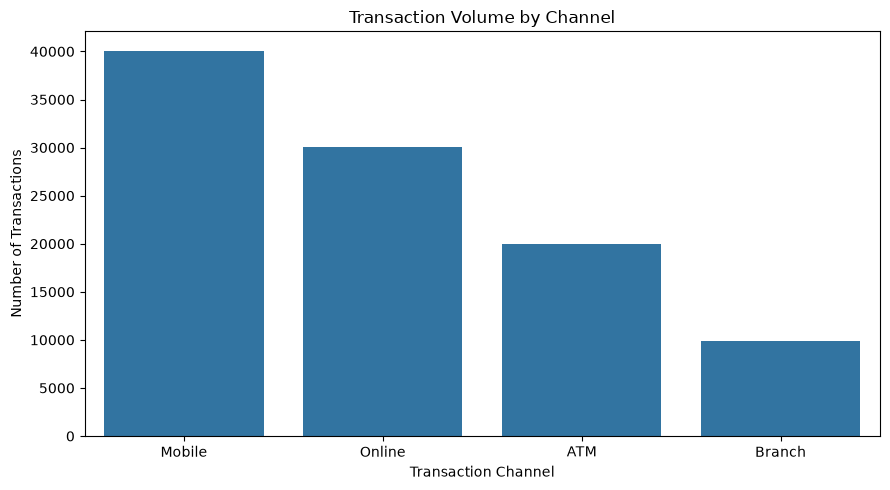

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_preference,
    x="channel",
    y="transactions"
)

plt.title("Transaction Volume by Channel")
plt.xlabel("Transaction Channel")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

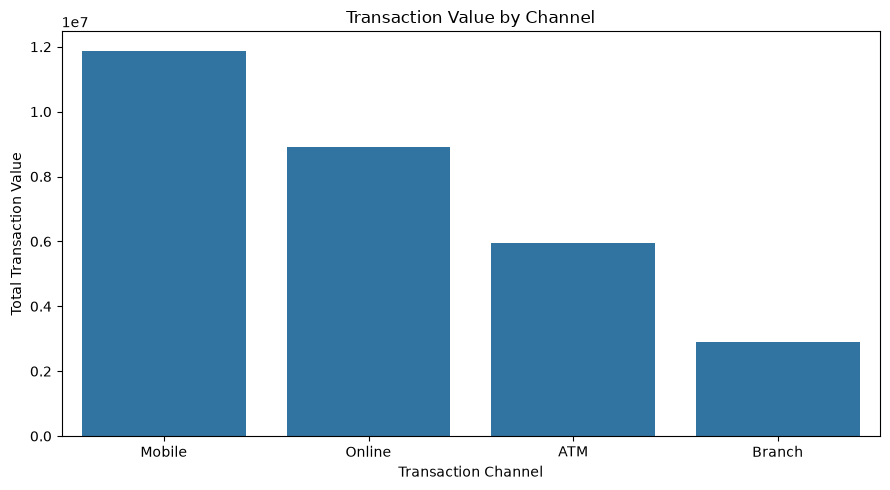

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=channel_preference,
    x="channel",
    y="total_value"
)

plt.title("Transaction Value by Channel")
plt.xlabel("Transaction Channel")
plt.ylabel("Total Transaction Value")

plt.tight_layout()
plt.show()

## 5.4 Loan Analysis

This section examines loan ownership, loan exposure, interest rates, repayment risk, and loan-related customer behavior.

In [13]:
loan_columns = [
    "loan_count",
    "total_loan_amount",
    "average_interest_rate",
    "late_loan_count",
    "default_loan_count",
    "loan_to_income_ratio"
]

customer_360[loan_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
loan_count,"5,000.00",0.39,0.66,0.00,0.00,0.00,1.00,5.00
total_loan_amount,"5,000.00","147,352.34","356,292.50",0.00,0.00,0.00,"104,560.43","3,322,170.32"
average_interest_rate,"5,000.00",3.24,5.13,0.00,0.00,0.00,8.03,16.48
late_loan_count,"5,000.00",0.06,0.26,0.00,0.00,0.00,0.00,3.00
default_loan_count,"5,000.00",0.01,0.12,0.00,0.00,0.00,0.00,1.00
loan_to_income_ratio,"5,000.00",3.41,7.80,0.00,0.00,0.00,3.06,98.34


In [14]:
# Loan ownership
loan_status = pd.Series({
    "Customers with Loans": (customer_360["loan_count"] > 0).sum(),
    "Customers without Loans": (customer_360["loan_count"] == 0).sum()
})

print(loan_status)

Customers with Loans       1519
Customers without Loans    3481
dtype: int64


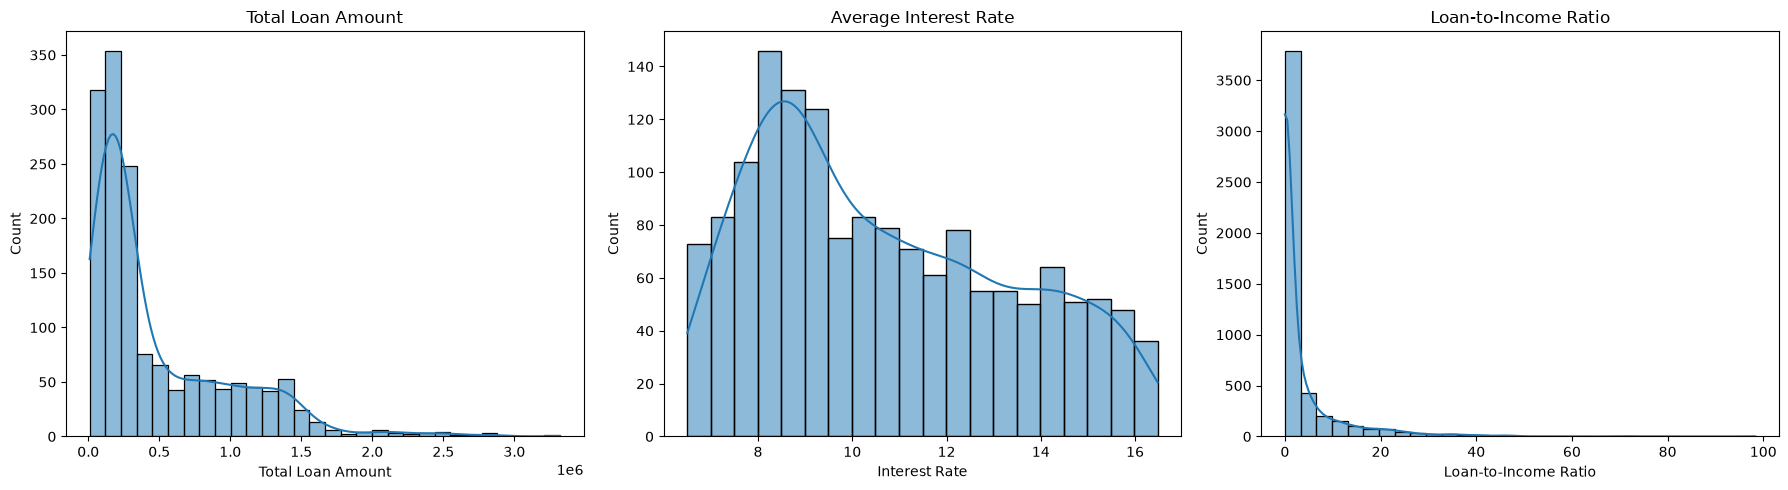

In [15]:
# Loan visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=customer_360[customer_360["loan_count"] > 0],
    x="total_loan_amount",
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Total Loan Amount")
axes[0].set_xlabel("Total Loan Amount")

sns.histplot(
    data=customer_360[customer_360["loan_count"] > 0],
    x="average_interest_rate",
    bins=20,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Average Interest Rate")
axes[1].set_xlabel("Interest Rate")

sns.histplot(
    data=customer_360,
    x="loan_to_income_ratio",
    bins=30,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Loan-to-Income Ratio")
axes[2].set_xlabel("Loan-to-Income Ratio")

plt.tight_layout()
plt.show()

In [16]:
# Loan risk
risk_summary = pd.Series({
    "Customers with Late Loans":
        (customer_360["late_loan_count"] > 0).sum(),

    "Customers with Defaults":
        (customer_360["default_loan_count"] > 0).sum()
})

print(risk_summary)

Customers with Late Loans    298
Customers with Defaults       70
dtype: int64


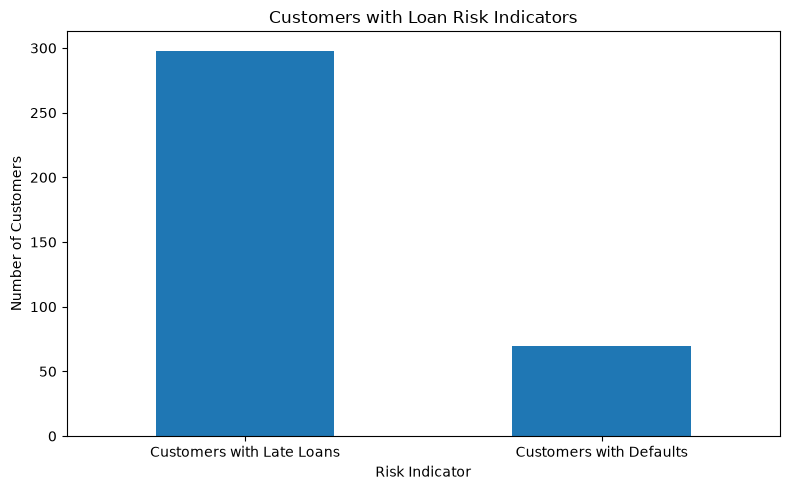

In [17]:
plt.figure(figsize=(8, 5))

risk_summary.plot(kind="bar")

plt.title("Customers with Loan Risk Indicators")
plt.xlabel("Risk Indicator")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

## 5.5 Customer Service Analysis

This section examines customer service interactions, complaints, escalations, and resolution performance to identify service-related patterns.

In [18]:
# Service summary
service_columns = [
    "total_service_interactions",
    "complaint_count",
    "escalated_count",
    "average_resolution_days"
]

customer_360[service_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
total_service_interactions,"5,000.00",1.56,1.51,0.00,0.00,1.00,3.00,9.00
complaint_count,"5,000.00",2.00,1.42,0.00,1.00,2.00,3.00,9.00
escalated_count,"5,000.00",0.12,0.35,0.00,0.00,0.00,0.00,2.00
average_resolution_days,"5,000.00",5.31,4.59,0.00,0.00,6.00,9.00,15.00


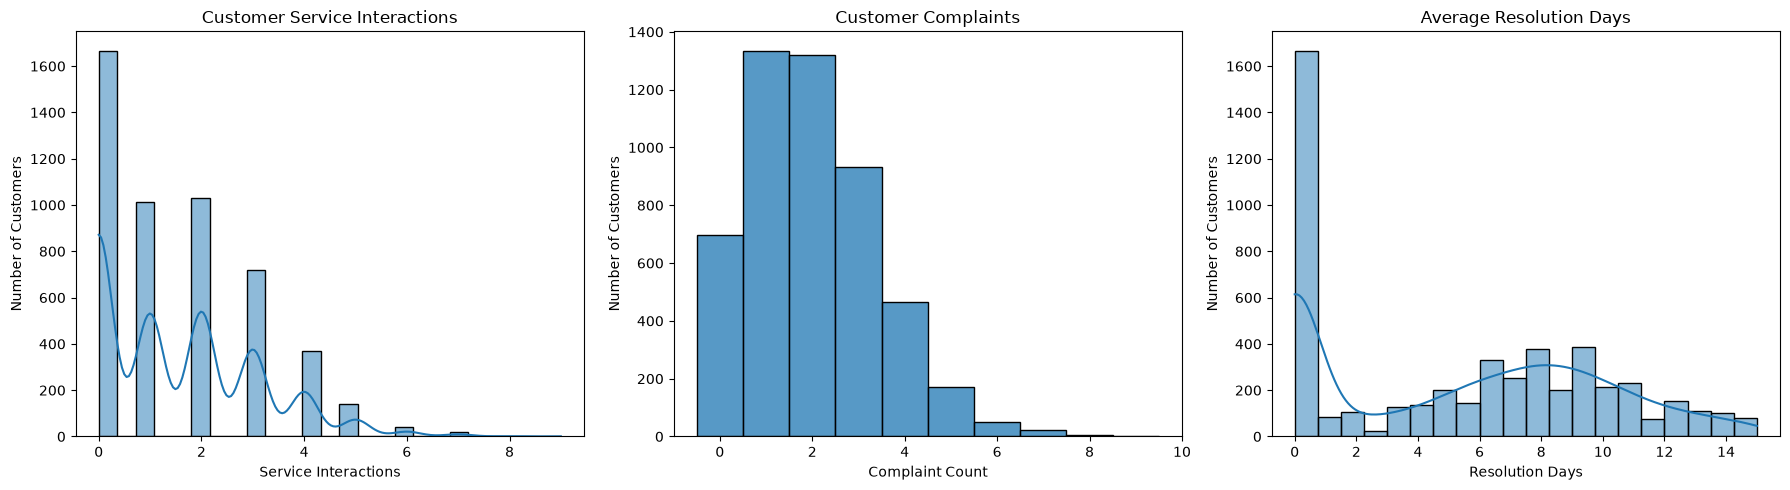

In [19]:
# Service activity visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=customer_360,
    x="total_service_interactions",
    bins=25,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Customer Service Interactions")
axes[0].set_xlabel("Service Interactions")
axes[0].set_ylabel("Number of Customers")

sns.histplot(
    data=customer_360,
    x="complaint_count",
    discrete=True,
    ax=axes[1]
)
axes[1].set_title("Customer Complaints")
axes[1].set_xlabel("Complaint Count")
axes[1].set_ylabel("Number of Customers")

sns.histplot(
    data=customer_360,
    x="average_resolution_days",
    bins=20,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Average Resolution Days")
axes[2].set_xlabel("Resolution Days")
axes[2].set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [20]:
# Escalation analysis
escalation_summary = pd.Series({
    "Customers with Complaints":
        (customer_360["complaint_count"] > 0).sum(),

    "Customers with Escalations":
        (customer_360["escalated_count"] > 0).sum()
})

print(escalation_summary)

Customers with Complaints     4303
Customers with Escalations     586
dtype: int64


## 5.6 Churn Analysis

This section examines customer churn and compares churned and retained customers across financial, transaction, product, and service characteristics.

In [22]:
print("Churn distribution:")
print(customer_360["churn"].value_counts())

print("\nChurn percentage:")
print(
    customer_360["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Churn distribution:
churn
0    3941
1    1059
Name: count, dtype: int64

Churn percentage:
churn
0   78.82
1   21.18
Name: proportion, dtype: float64


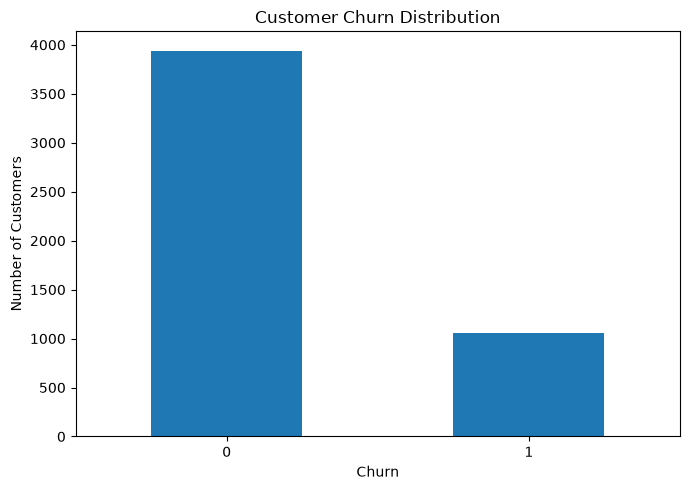

In [23]:
# Churn visualization
plt.figure(figsize=(7, 5))

customer_360["churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [24]:
# Churn vs key customer metrics
churn_comparison = (
    customer_360
    .groupby("churn")[
        [
            "age",
            "annual_income",
            "credit_score",
            "account_count",
            "total_transactions",
            "total_transaction_value",
            "products_number",
            "total_balance",
            "total_loan_amount",
            "complaint_count",
            "total_service_interactions",
            "recency_days"
        ]
    ]
    .mean()
    .round(2)
)

churn_comparison

,age,annual_income,credit_score,account_count,total_transactions,total_transaction_value,products_number,total_balance,total_loan_amount,complaint_count,total_service_interactions,recency_days
churn,,,,,,,,,,,,
0,45.27,"66,493.83",653.97,1.60,16.32,"4,845.62",2.10,"92,467.95","156,206.19",1.92,1.58,17.27
1,46.05,"64,959.68",647.24,1.12,12.35,"3,597.61",1.62,"61,623.19","114,403.28",2.30,1.49,19.68


## 5.7 Correlation Analysis

Correlation analysis is used to identify relationships between important numerical customer attributes and support further business interpretation.

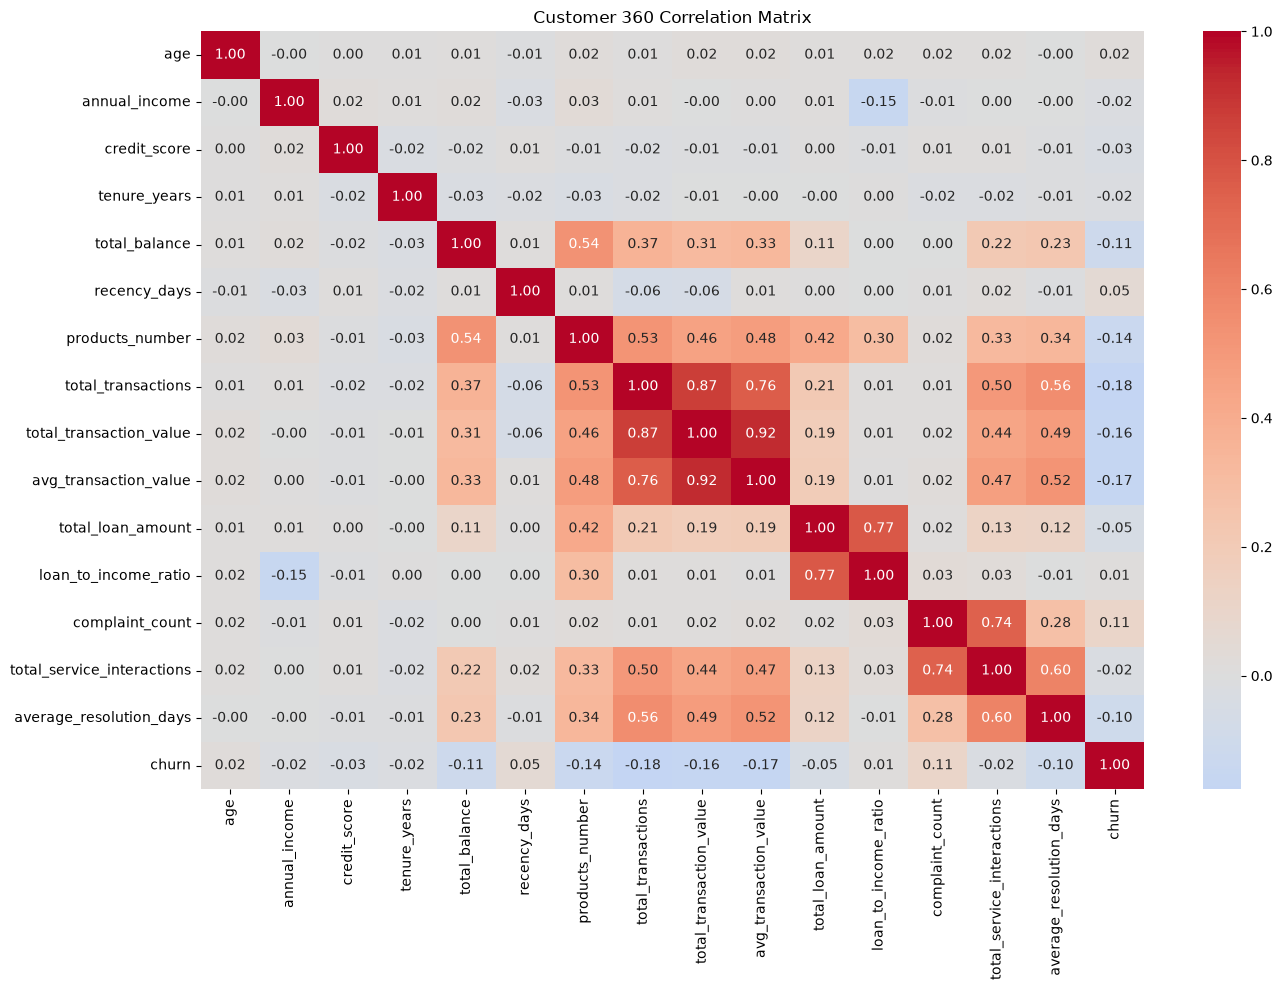

In [25]:
correlation_columns = [
    "age",
    "annual_income",
    "credit_score",
    "tenure_years",
    "total_balance",
    "recency_days",
    "products_number",
    "total_transactions",
    "total_transaction_value",
    "avg_transaction_value",
    "total_loan_amount",
    "loan_to_income_ratio",
    "complaint_count",
    "total_service_interactions",
    "average_resolution_days",
    "churn"
]

correlation_matrix = customer_360[correlation_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Customer 360 Correlation Matrix")
plt.tight_layout()
plt.show()

In [30]:
churn_correlations = (
    correlation_matrix["churn"]
    .drop("churn")
    .sort_values(key=abs, ascending=False)
)

churn_correlations

total_transactions           -0.18
avg_transaction_value        -0.17
total_transaction_value      -0.16
products_number              -0.14
total_balance                -0.11
complaint_count               0.11
average_resolution_days      -0.10
recency_days                  0.05
total_loan_amount            -0.05
credit_score                 -0.03
total_service_interactions   -0.02
age                           0.02
annual_income                -0.02
tenure_years                 -0.02
loan_to_income_ratio          0.01
Name: churn, dtype: float64

## 5.8 Key Business Insights

The exploratory analysis provides insights into customer demographics, financial behavior, banking engagement, loan exposure, service experience, and churn.

In [28]:
print("CUSTOMER 360 BUSINESS SUMMARY")
print("=" * 50)

print(f"Total customers: {len(customer_360):,}")

print(
    f"Average age: "
    f"{customer_360['age'].mean():.1f}"
)

print(
    f"Average annual income: "
    f"{customer_360['annual_income'].mean():,.2f}"
)

print(
    f"Average credit score: "
    f"{customer_360['credit_score'].mean():.1f}"
)

print(
    f"Customers with loans: "
    f"{(customer_360['loan_count'] > 0).sum():,}"
)

print(
    f"Customers with complaints: "
    f"{(customer_360['complaint_count'] > 0).sum():,}"
)

print(
    f"Customers with escalations: "
    f"{(customer_360['escalated_count'] > 0).sum():,}"
)

print(
    f"Churned customers: "
    f"{(customer_360['churn'] > 0).sum():,}"
)

print(
    f"Average transactions per customer: "
    f"{customer_360['total_transactions'].mean():.2f}"
)

print(
    f"Average products per customer: "
    f"{customer_360['products_number'].mean():.2f}"
)

CUSTOMER 360 BUSINESS SUMMARY
Total customers: 5,000
Average age: 45.4
Average annual income: 66,168.90
Average credit score: 652.5
Customers with loans: 1,519
Customers with complaints: 4,303
Customers with escalations: 586
Churned customers: 1,059
Average transactions per customer: 15.48
Average products per customer: 2.00


## 5.9 EDA Conclusion

The exploratory analysis provides a consolidated view of the bank's customer base across demographics, financial characteristics, account and transaction behavior, loan exposure, customer service activity, and churn.

The analysis highlights differences in customer engagement, financial exposure, service usage, and churn behavior. These findings provide the foundation for the next stages of the project, including customer segmentation, churn analysis/modeling, business recommendations, and dashboard development.